# Video-to-Text (VTT) — local vision-language models on Apple Silicon

Pick a **model family** (Qwen2-VL, Qwen2.5-VL, SmolVLM2) and a **size** (SMALL / MEDIUM / LARGE), then run the pipeline
end to end:

1. Select the model from the `MODEL_NAME` registry (`APPLE → VTT → FAMILY → SIZE`)
2. Review every family and size: parameters, memory and how video is handled
3. Load the model
4. Load the video prompts (`prompts/videos_vtt_prompts/vtt_prompts_10.csv`: 10 openly licensed clips from Wikimedia Commons, each with a question)
5. Generate an answer for every video, measuring speed, memory and energy, with per-prompt macmon capture
6. Save the responses
7. Measure the cost of the run, per video and in total
8. Compare SMALL / MEDIUM / LARGE of the selected family side by side
9. Combine every model run so far

All models run on **MLX** on the Apple GPU through [`mlx-vlm`](https://github.com/Blaizzy/mlx-vlm). Videos are
sampled at `FPS` frames per second (1 by default), so a 10-second clip becomes about 10 frames.

**MLX compatibility.** Both models from the original registry are supported, including video input:
**Qwen2-VL-2B-Instruct** and **Qwen2-VL-7B-Instruct** (`mlx-community/...-4bit`).

## 1. Configuration — model registry

In [1]:
import os
import sys
from pathlib import Path

# Run from the project root, whether this notebook is opened from notebooks/ or from the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'prompts').is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# APPLE -> VTT -> family -> size -> model
MODEL_NAME = {
    'APPLE': {
        'VTT': {
            'Qwen2-VL': {                              # original registry
                'SMALL': 'Qwen2-VL-2B-Instruct',       #  2.2B
                'LARGE': 'Qwen2-VL-7B-Instruct',       #  8.3B
            },
            'Qwen2.5-VL': {
                'SMALL': 'Qwen2.5-VL-3B-Instruct',     #  3.8B
                'MEDIUM': 'Qwen2.5-VL-7B-Instruct',    #  8.3B
                'LARGE': 'Qwen2.5-VL-32B-Instruct',    # 33.5B
            },
            'SmolVLM2': {                              # Hugging Face's video-tuned small models
                'SMALL': 'SmolVLM2-256M-Video-Instruct',   # 0.26B
                'MEDIUM': 'SmolVLM2-500M-Video-Instruct',  # 0.51B
                'LARGE': 'SmolVLM2-2.2B-Instruct',         # 2.2B
            },
        },
    },
}

# Model -> MLX checkpoint (Qwen models 4-bit)
MLX_REPOS = {
    'Qwen2-VL-2B-Instruct':    'mlx-community/Qwen2-VL-2B-Instruct-4bit',
    'Qwen2-VL-7B-Instruct':    'mlx-community/Qwen2-VL-7B-Instruct-4bit',
    'Qwen2.5-VL-3B-Instruct':  'mlx-community/Qwen2.5-VL-3B-Instruct-4bit',
    'Qwen2.5-VL-7B-Instruct':  'mlx-community/Qwen2.5-VL-7B-Instruct-4bit',
    'Qwen2.5-VL-32B-Instruct': 'mlx-community/Qwen2.5-VL-32B-Instruct-4bit',
    # SmolVLM2 is only published in 16-bit for MLX (it is small enough not to need quantization)
    'SmolVLM2-256M-Video-Instruct': 'mlx-community/SmolVLM2-256M-Video-Instruct-mlx',
    'SmolVLM2-500M-Video-Instruct': 'mlx-community/SmolVLM2-500M-Video-Instruct-mlx',
    'SmolVLM2-2.2B-Instruct':       'mlx-community/SmolVLM2-2.2B-Instruct-mlx',
}

PLATFORM, TASK = 'APPLE', 'VTT'
# Environment variables VTT_FAMILY / VTT_SIZE / VTT_PROMPTS / VTT_COMPARE / VTT_MAX_TOKENS / VTT_FPS override these
FAMILY = os.environ.get('VTT_FAMILY', 'Qwen2-VL')   # 'Qwen2-VL' | 'Qwen2.5-VL' | 'SmolVLM2'
SIZE = os.environ.get('VTT_SIZE', 'LARGE')          # 'SMALL' | 'MEDIUM' | 'LARGE' (only the sizes listed above)
RUN_FAMILY_COMPARISON = os.environ.get('VTT_COMPARE', '1') == '1'   # section 8: also run the family's other sizes

model_name = MODEL_NAME[PLATFORM][TASK][FAMILY][SIZE]
repo = MLX_REPOS[model_name]

# Prompt set: a CSV in prompts/videos_vtt_prompts/ with columns id,video,prompt (+ source, author and licence of each clip)
PROMPT_SET = os.environ.get('VTT_PROMPTS', 'vtt_prompts_10')
INPUT_PATH = Path('prompts/videos_vtt_prompts') / f'{PROMPT_SET}.csv'
FPS = float(os.environ.get('VTT_FPS', '1.0'))   # frames sampled per second of video
OUTPUT_DIR = Path('outputs/vtt') / FAMILY   # outputs/vtt/<family>/<params>/<prompt set>/ (see out_dir, section 2)
MAX_NEW_TOKENS = min(int(os.environ.get('VTT_MAX_TOKENS', '1024')), 1024)   # hard cap: no response exceeds 1024 output tokens
POWER_SAMPLE_MS = 100            # macmon sampling interval (its fastest is ~110 ms)
ELECTRICITY_USD_PER_KWH = 0.15   # your electricity price, for the $ per 1M tokens figures

print(f'{PLATFORM} / {TASK} / {FAMILY} / {SIZE} -> {model_name} -> {repo}')
print(f'Prompt set: {INPUT_PATH}  |  {FPS:g} frame(s) per second  |  max new tokens: {MAX_NEW_TOKENS}')

APPLE / VTT / Qwen2.5-VL / LARGE -> Qwen2.5-VL-32B-Instruct -> mlx-community/Qwen2.5-VL-32B-Instruct-4bit
Prompt set: prompts/videos_vtt_prompts/vtt_prompts_10.csv  |  1 frame(s) per second  |  max new tokens: 1024


## 2. Model families — sizes, memory and how video is handled

Parameter counts come from each original checkpoint's safetensors metadata on Hugging Face.

- **Qwen2-VL / Qwen2.5-VL** take video natively: the sampled frames are grouped in pairs over time and encoded at
  their own resolution, so a longer clip means proportionally more input tokens.
- **SmolVLM2** is Hugging Face's small model tuned for video; its sampled frames are passed as a sequence of images at up
  to 512 px, without tiling (SmolVLM2's own video settings), about 67 tokens per frame.

**What an input costs for a local model.** There is **no per-token fee ($0)**. What each video and question costs is
**time** (time to first token, which includes reading every sampled frame), **memory** and **energy** (section 7).

In [2]:
import mlx.core as mx
import pandas as pd

GB = 1e9
DEVICE = mx.device_info()
GPU_BUDGET_GB = DEVICE['max_recommended_working_set_size'] / GB

SPECS = pd.DataFrame([
    # model,                         params,          video handling,                  precision, download_gb
    ('Qwen2-VL-2B-Instruct',         2_208_985_600,   'native video (frame pairs)',    '4-bit',  1.26),
    ('Qwen2-VL-7B-Instruct',         8_291_375_616,   'native video (frame pairs)',    '4-bit',  4.68),
    ('Qwen2.5-VL-3B-Instruct',       3_754_622_976,   'native video (frame pairs)',    '4-bit',  3.09),
    ('Qwen2.5-VL-7B-Instruct',       8_292_166_656,   'native video (frame pairs)',    '4-bit',  5.65),
    ('Qwen2.5-VL-32B-Instruct',      33_452_718_336,  'native video (frame pairs)',    '4-bit', 19.83),
    ('SmolVLM2-256M-Video-Instruct', 256_484_928,     'frames as an image sequence',   '16-bit', 0.51),
    ('SmolVLM2-500M-Video-Instruct', 507_482_304,     'frames as an image sequence',   '16-bit', 1.02),
    ('SmolVLM2-2.2B-Instruct',       2_246_784_880,   'frames as an image sequence',   '16-bit', 4.49),
], columns=['model', 'params', 'video_handling', 'precision', 'download_gb']).set_index('model')

# Output subfolder per model, named by its parameter count: outputs/vtt/<family>/<params>/<prompt set>/
PARAM_FOLDER = {'Qwen2-VL-2B-Instruct': '2B', 'Qwen2-VL-7B-Instruct': '7B', 'Qwen2.5-VL-3B-Instruct': '3B',
                'Qwen2.5-VL-7B-Instruct': '7B', 'Qwen2.5-VL-32B-Instruct': '32B', 'SmolVLM2-256M-Video-Instruct': '256M',
                'SmolVLM2-500M-Video-Instruct': '500M', 'SmolVLM2-2.2B-Instruct': '2.2B'}

def family_of(name):
    return next(f for f, sizes in MODEL_NAME[PLATFORM][TASK].items() if name in sizes.values())

def size_of(name):
    return next(sz for sizes in MODEL_NAME[PLATFORM][TASK].values() for sz, n in sizes.items() if n == name)

def out_dir(name):
    d = OUTPUT_DIR / PARAM_FOLDER[name] / PROMPT_SET
    d.mkdir(parents=True, exist_ok=True)
    return d

rows = []
for family, sizes in MODEL_NAME[PLATFORM][TASK].items():
    for size, name in sizes.items():
        s = SPECS.loc[name]
        rows.append({
            '': '▶' if name == model_name else '',
            'Family': family, 'Size': size, 'Model': name,
            'Params (B)': f'{s.params / 1e9:.2f}',
            'Precision': s.precision,
            'Weights (GB)': f'{s.download_gb:.2f}',
            'Video handling': s.video_handling,
            'Fits this Mac': 'yes' if s.download_gb < GPU_BUDGET_GB * 0.9 else 'no',
            'MLX checkpoint': MLX_REPOS[name],
            'API cost': '$0 (local)',
        })
print(f"{DEVICE['device_name']}: {DEVICE['memory_size'] / GB:.0f} GB unified memory, "
      f"{GPU_BUDGET_GB:.1f} GB usable by the GPU by default.  ▶ = selected model")
pd.DataFrame(rows).style.hide(axis='index')

Apple M5 Max: 52 GB unified memory, 40.2 GB usable by the GPU by default.  ▶ = selected model


,Family,Size,Model,Params (B),Precision,Weights (GB),Video handling,Fits this Mac,MLX checkpoint,API cost
,Qwen2-VL,SMALL,Qwen2-VL-2B-Instruct,2.21,4-bit,1.26,native video (frame pairs),yes,mlx-community/Qwen2-VL-2B-Instruct-4bit,$0 (local)
,Qwen2-VL,LARGE,Qwen2-VL-7B-Instruct,8.29,4-bit,4.68,native video (frame pairs),yes,mlx-community/Qwen2-VL-7B-Instruct-4bit,$0 (local)
,Qwen2.5-VL,SMALL,Qwen2.5-VL-3B-Instruct,3.75,4-bit,3.09,native video (frame pairs),yes,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,$0 (local)
,Qwen2.5-VL,MEDIUM,Qwen2.5-VL-7B-Instruct,8.29,4-bit,5.65,native video (frame pairs),yes,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,$0 (local)
▶,Qwen2.5-VL,LARGE,Qwen2.5-VL-32B-Instruct,33.45,4-bit,19.83,native video (frame pairs),yes,mlx-community/Qwen2.5-VL-32B-Instruct-4bit,$0 (local)
,SmolVLM2,SMALL,SmolVLM2-256M-Video-Instruct,0.26,16-bit,0.51,frames as an image sequence,yes,mlx-community/SmolVLM2-256M-Video-Instruct-mlx,$0 (local)
,SmolVLM2,MEDIUM,SmolVLM2-500M-Video-Instruct,0.51,16-bit,1.02,frames as an image sequence,yes,mlx-community/SmolVLM2-500M-Video-Instruct-mlx,$0 (local)
,SmolVLM2,LARGE,SmolVLM2-2.2B-Instruct,2.25,16-bit,4.49,frames as an image sequence,yes,mlx-community/SmolVLM2-2.2B-Instruct-mlx,$0 (local)


## 3. Load the model

In [3]:
import json
import time
from mlx_vlm import load, stream_generate
from mlx_vlm.prompt_utils import apply_chat_template

def load_vlm(name):
    t0 = time.perf_counter()
    model, processor = load(MLX_REPOS[name])
    mx.eval(model.parameters())
    return model, processor, time.perf_counter() - t0

model, processor, load_seconds = load_vlm(model_name)
spec = SPECS.loc[model_name]
print(f'Loaded {repo} in {load_seconds:.1f}s on {mx.default_device()}')
print(f'Parameters: {spec.params / 1e9:.2f}B  |  video: {spec.video_handling}')
print(f'Weights in memory: {mx.get_active_memory() / GB:.2f} GB ({spec.precision})')

/Users/genailab/mlx-projects/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Fetching 16 files: 100%|██████████| 16/16 [00:00<00:00, 2384.14it/s]

Loaded mlx-community/Qwen2.5-VL-32B-Instruct-4bit in 2.4s on Device(gpu, 0)
Parameters: 33.45B  |  video: native video (frame pairs)
Weights in memory: 19.81 GB (4-bit)


## 4. Load the video prompts

Each row of `prompts/videos_vtt_prompts/<prompt set>.csv` is one clip and the question asked about it. The 10 clips are openly licensed
videos from Wikimedia Commons (source, author and licence are in the CSV), trimmed to 10 seconds (clip 02 to 30 seconds)
and scaled to 480 pixels high. Each clip is sampled at `FPS` frames per second.

In [4]:
import cv2
from PIL import Image
from IPython.display import display

PROMPTS = pd.read_csv(INPUT_PATH, dtype={'id': str})
PROMPTS['id'] = PROMPTS['id'].str.zfill(2)

def video_info(path):
    cap = cv2.VideoCapture(path)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frames, fps = cap.get(cv2.CAP_PROP_FRAME_COUNT), cap.get(cv2.CAP_PROP_FPS)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frames // 2)
    ok, mid = cap.read()
    cap.release()
    return f'{w}x{h}', frames / fps, Image.fromarray(cv2.cvtColor(mid, cv2.COLOR_BGR2RGB)) if ok else None

info = [video_info(v) for v in PROMPTS.video]
PROMPTS['resolution'] = [i[0] for i in info]
PROMPTS['duration_s'] = [round(i[1], 1) for i in info]
print(f'Prompt set: {INPUT_PATH} ({len(PROMPTS)} videos, {PROMPTS.duration_s.sum():.0f} s in total)')
pd.DataFrame({'id': PROMPTS.id, 'duration (s)': PROMPTS.duration_s, 'resolution (px)': PROMPTS.resolution,
              'source': PROMPTS.source_title, 'licence': PROMPTS.license, 'prompt': PROMPTS.prompt}).style.hide(axis='index')

Prompt set: prompts/videos_vtt_prompts/vtt_prompts_10.csv (10 videos, 120 s in total)


id,duration (s),resolution (px),source,licence,prompt
01,10.000000,854x480,Cat playing with a round track toy.webm,CC BY-SA 3.0,Describe what happens in this video in detail.
02,30.000000,854x480,Road traffic on Stritarjeva street.webm,CC BY 3.0,Describe what happens in this video in detail.
03,9.900000,854x480,Ocean Shores - Waves &Seagulls 2015-06 303 (90 Sec).ogv,CC BY-SA 4.0,Describe what happens in this video in detail.
04,10.000000,854x480,Birds flying behind a ferry.webm,CC BY-SA 3.0,Describe what happens in this video in detail.
05,10.000000,854x480,Fireworks zocalo.webm,CC BY-SA 4.0,Describe what happens in this video in detail.
06,10.000000,854x480,Traditional kitchen in Northern Ghana.webm,CC BY-SA 4.0,Describe what happens in this video in detail.
07,10.000000,854x480,ED9MK-0103 train on route Kazan-Izhevsk at the station Mozhga.webm,CC BY 3.0,Describe what happens in this video in detail.
08,10.000000,854x480,Big Buck Bunny - closing credits.webm,CC BY 3.0,Describe what happens in this video in detail.
09,10.000000,480x480,Test Kitchen- Pork Belly Sandwich.webm,CC BY 3.0,Describe what happens in this video in detail.
10,10.000000,854x480,"Waves crashing on rocks off Beach 4, Kalaloch Beach, Washington 01.webm",CC BY-SA 4.0,Describe what happens in this video in detail.


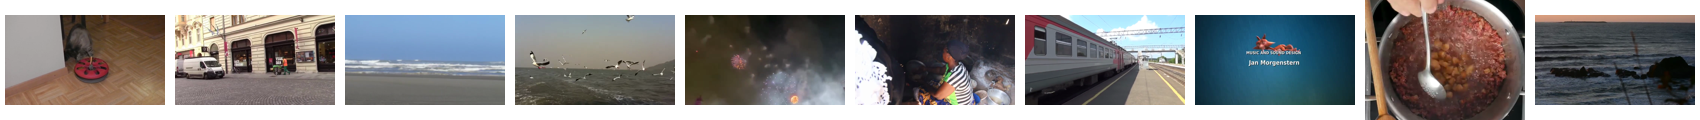

In [5]:
# The middle frame of each clip
thumbs = []
for _, _, mid in info:
    mid = mid.copy()
    mid.thumbnail((160, 160))
    thumbs.append(mid)
sheet = Image.new('RGB', (170 * len(thumbs), 120), 'white')
for i, im in enumerate(thumbs):
    sheet.paste(im, (170 * i + (170 - im.width) // 2, (120 - im.height) // 2))
display(sheet)

## 5. Generate

Greedy decoding (temperature 0), so results are reproducible. Each video is a separate conversation: the model's chat
template with one video (sampled at `FPS` frames per second) and the prompt.

**Power monitoring.** `macmon` (no sudo needed) runs in the background for the whole notebook, sampling the chip's
power sensors about every 110 ms. Each run's energy is split into the **prefill** window (reading the frames and
prompt, up to the first output token) and the **decode** window (generating). If `macmon` isn't installed, the power
metrics are left empty and everything else runs. Readings are Apple's on-chip estimates, not a wall-meter measurement.

In [6]:
import atexit
import json
import shutil
import subprocess
import threading

class PowerMonitor:
    """Runs `macmon pipe` in the background and keeps every sample.

    Each sample is the average over the interval since the previous one, so the energy in any time
    window is the sum of power x (overlap of that interval with the window).
    """
    def __init__(self, interval_ms):
        self.samples = []  # (time.perf_counter(), macmon sample dict)
        self.available = shutil.which('macmon') is not None
        if not self.available:
            print('macmon not found: power and energy metrics will be empty (install: brew install macmon)')
            return
        self.proc = subprocess.Popen(['macmon', 'pipe', '-i', str(interval_ms)],
                                     stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
        atexit.register(self.proc.terminate)
        threading.Thread(target=self._read, daemon=True).start()
        t_start = time.perf_counter()
        while len(self.samples) < 2 and time.perf_counter() - t_start < 5:  # macmon takes ~0.7 s to start
            time.sleep(0.05)
        self.available = len(self.samples) >= 2

    def _read(self):
        for line in self.proc.stdout:
            try:
                self.samples.append((time.perf_counter(), json.loads(line)))
            except json.JSONDecodeError:
                pass

    def wait_past(self, t, timeout=2.0):
        """Block until a sample covering time t has arrived."""
        deadline = time.perf_counter() + timeout
        while self.samples[-1][0] < t and time.perf_counter() < deadline:
            time.sleep(0.02)

    def window(self, a, b):
        """Samples overlapping [a, b], as (seconds of overlap, sample)."""
        return [(min(t, b) - max(t_prev, a), s)
                for (t_prev, _), (t, s) in zip(self.samples, self.samples[1:])
                if min(t, b) - max(t_prev, a) > 0]

def soc_power(s):
    return s['all_power'] + s['ram_power']  # CPU + GPU + Neural Engine + memory, in watts

def integrate(win, fn):
    return sum(overlap * fn(s) for overlap, s in win)

POWER_KEYS = ['gpu_util_avg_pct', 'gpu_util_peak_pct', 'gpu_freq_avg_mhz', 'gpu_power_avg_w', 'gpu_power_peak_w',
              'soc_power_avg_w', 'gpu_temp_max_c', 'energy_j', 'energy_net_j',
              'prefill_energy_mj_per_input_token', 'decode_energy_mj_per_output_token', 'power_samples']

def summarize_power(t0, t_first, t_end, n_input, n_output):
    if not POWER.available:
        return dict.fromkeys(POWER_KEYS)
    POWER.wait_past(t_end)
    run = POWER.window(t0, t_end)
    samples = [s for _, s in run]
    dur = t_end - t0
    e_soc = integrate(run, soc_power)
    return {
        'gpu_util_avg_pct': round(100 * integrate(run, lambda s: s['gpu_active_ratio']) / dur, 1),
        'gpu_util_peak_pct': round(100 * max(s['gpu_active_ratio'] for s in samples), 1),
        'gpu_freq_avg_mhz': round(integrate(run, lambda s: s['gpu_freq_mhz']) / dur),
        'gpu_power_avg_w': round(integrate(run, lambda s: s['gpu_power']) / dur, 1),
        'gpu_power_peak_w': round(max(s['gpu_power'] for s in samples), 1),
        'soc_power_avg_w': round(e_soc / dur, 1),
        'gpu_temp_max_c': round(max(s['temp']['gpu_temp_avg'] for s in samples), 1),
        'energy_j': round(e_soc, 2),
        'energy_net_j': round(e_soc - IDLE_SOC_W * dur, 2),
        'prefill_energy_mj_per_input_token': round(1000 * integrate(POWER.window(t0, t_first), soc_power) / n_input, 3),
        'decode_energy_mj_per_output_token': round(1000 * integrate(POWER.window(t_first, t_end), soc_power) / max(n_output, 1), 2),
        'power_samples': len(run),
    }

POWER = PowerMonitor(POWER_SAMPLE_MS)
if POWER.available:
    time.sleep(1.0)  # idle baseline, measured with the model loaded but not running
    a, b = POWER.samples[0][0], POWER.samples[-1][0]
    IDLE_SOC_W = integrate(POWER.window(a, b), soc_power) / (b - a)
    print(f'Power monitor running (macmon, ~{POWER_SAMPLE_MS} ms samples). Idle chip power: {IDLE_SOC_W:.2f} W')

def cpu_clusters():
    """CPU cluster names and core counts from macOS (e.g. M5 Max: 6 'Super' + 12 'Performance' cores)."""
    def sysctl(key):
        return subprocess.run(['sysctl', '-n', key], capture_output=True, text=True).stdout.strip()
    return [(sysctl(f'hw.perflevel{i}.name') or f'level{i}', int(sysctl(f'hw.perflevel{i}.logicalcpu') or 0)) for i in (0, 1)]

CPU_CLUSTERS = cpu_clusters()
HARDWARE = {}   # model name -> hardware_metrics() for its whole run

def hardware_metrics(t0, t1):
    """GPU, CPU, Neural Engine (NPU), memory and whole-chip activity over [t0, t1], from the macmon samples.

    macmon calls the two CPU clusters 'pcpu' (perflevel0) and 'ecpu' (perflevel1); they are reported here
    under the names macOS gives them.
    """
    if not POWER.available:
        return None
    POWER.wait_past(t1)
    win = POWER.window(t0, t1)
    samples = [s for _, s in win]
    dur = t1 - t0
    avg = lambda fn: integrate(win, fn) / dur
    peak = lambda fn: max(fn(s) for s in samples)
    energy = lambda fn: round(integrate(win, fn), 2)
    pct = lambda x: round(100 * x, 1)
    (c0_name, c0_cores), (c1_name, c1_cores) = CPU_CLUSTERS
    c0, c1 = c0_name.lower(), c1_name.lower()
    ane = lambda s: s['ane_power']
    return {
        'gpu': {
            'avg_utilization_pct': pct(avg(lambda s: s['gpu_active_ratio'])),
            'peak_utilization_pct': pct(peak(lambda s: s['gpu_active_ratio'])),
            'avg_frequency_mhz': round(avg(lambda s: s['gpu_freq_mhz'])),
            'max_frequency_mhz': round(peak(lambda s: s['gpu_freq_mhz'])),
            'avg_power_watts': round(avg(lambda s: s['gpu_power']), 1),
            'peak_power_watts': round(peak(lambda s: s['gpu_power']), 1),
            'energy_joules': energy(lambda s: s['gpu_power']),
            'avg_temperature_c': round(avg(lambda s: s['temp']['gpu_temp_avg']), 1),
            'max_temperature_c': round(peak(lambda s: s['temp']['gpu_temp_avg']), 1),
        },
        'cpu': {
            'avg_utilization_pct': pct(avg(lambda s: s['cpu_active_ratio'])),
            'peak_utilization_pct': pct(peak(lambda s: s['cpu_active_ratio'])),
            f'{c0}_cores': c0_cores,
            f'{c0}_cores_avg_utilization_pct': pct(avg(lambda s: s['pcpu_active_ratio'])),
            f'{c0}_cores_avg_frequency_mhz': round(avg(lambda s: s['pcpu_freq_mhz'])),
            f'{c1}_cores': c1_cores,
            f'{c1}_cores_avg_utilization_pct': pct(avg(lambda s: s['ecpu_active_ratio'])),
            f'{c1}_cores_avg_frequency_mhz': round(avg(lambda s: s['ecpu_freq_mhz'])),
            'avg_power_watts': round(avg(lambda s: s['cpu_power']), 1),
            'peak_power_watts': round(peak(lambda s: s['cpu_power']), 1),
            'energy_joules': energy(lambda s: s['cpu_power']),
            'avg_temperature_c': round(avg(lambda s: s['temp']['cpu_temp_avg']), 1),
            'max_temperature_c': round(peak(lambda s: s['temp']['cpu_temp_avg']), 1),
        },
        'npu': {
            'name': 'Apple Neural Engine (ANE)',
            'used': peak(ane) > 0.05,
            'avg_power_watts': round(avg(ane), 2),
            'peak_power_watts': round(peak(ane), 2),
            'energy_joules': energy(ane),
            'note': 'MLX runs models on the GPU, so the Neural Engine stays idle (about 0 W) during these runs.',
        },
        'system_memory': {
            'avg_power_watts': round(avg(lambda s: s['ram_power']), 1),
            'energy_joules': energy(lambda s: s['ram_power']),
            'ram_total_gb': round(samples[0]['memory']['ram_total'] / 1e9, 1),
            'avg_ram_used_gb': round(avg(lambda s: s['memory']['ram_usage']) / 1e9, 1),
            'peak_ram_used_gb': round(peak(lambda s: s['memory']['ram_usage']) / 1e9, 1),
            'peak_swap_used_gb': round(peak(lambda s: s['memory']['swap_usage']) / 1e9, 2),
            'note': 'RAM used is for the whole Mac, including other apps, not just this model.',
        },
        'whole_chip': {
            'avg_power_watts': round(avg(soc_power), 1),
            'peak_power_watts': round(peak(soc_power), 1),
            'energy_joules': energy(soc_power),
            'idle_power_watts': round(IDLE_SOC_W, 2),
            'note': 'CPU + GPU + Neural Engine + memory.',
        },
        'measured_seconds': round(dur, 2),
        'power_samples': len(win),
    }

Power monitor running (macmon, ~100 ms samples). Idle chip power: 0.40 W


### Per-prompt metrics analysis

Every video is wrapped in `metrics_monitor_start()` / `metrics_monitor_stop()` from `macmon_metrics/metrics_monitor.py`,
which records a macmon time series for that video. Results go to a separate folder,
`metrics_analysis/vtt/<family>/<params>/<prompt set>/`:

- `System_Level_Metrics/<prompt id>_system_metrics.csv`: CPU / GPU / NPU utilisation, power and temperature, RAM used
  and total system power, sampled every 100 ms while that video was processed
- `Model_Level_Metrics/<model>_prompt_metrics.csv`: one row per video with its length, frames sampled, input tokens
  (text + frames), output tokens, the first token generated and its latency, prompt processing rate, inference rate
  and inference time, followed by the video, prompt and response

Section 9 combines every model's `Model_Level_Metrics` CSV into `metrics_analysis/vtt/all_models_prompt_metrics_<prompt set>.csv`.

In [7]:
import macmon_metrics.metrics_monitor as mm
from macmon_metrics.metrics_monitor import metrics_monitor_start, metrics_monitor_stop, setup_output_directory

METRICS_ROOT = Path('metrics_analysis/vtt')

def analysis_dirs(name):
    """(System_Level_Metrics, Model_Level_Metrics) folders for one model and prompt set."""
    return setup_output_directory(str(METRICS_ROOT / family_of(name) / PARAM_FOLDER[name] / PROMPT_SET))

# Start the macmon tracker now: it takes about a second to produce its first sample, and starting it here means
# every video's capture has samples from its first moment.
if mm._tracker is None:
    mm._tracker = mm.MacMonTracker(binary_path=mm._resolve_macmon_binary())
    mm._tracker.start()
    time.sleep(1.5)

from mlx_vlm.generate.video import processor_handles_video, resolve_video_inputs
from mlx_vlm.utils import VideoSampling, load_video

def video_media(processor, video):
    """How the clip is passed to the model: native video (Qwen) or its sampled frames as an image sequence (SmolVLM2)."""
    if processor_handles_video(processor):
        frames = load_video(video, VideoSampling(fps=FPS))[0].shape[0]
        return dict(video=[video], fps=FPS), {'num_images': 0, 'video': video, 'fps': FPS}, frames
    # SmolVLM2's own video settings: frames at up to 512 px, not tiled (tiling would make each frame ~860 tokens)
    if hasattr(processor.image_processor, 'do_image_splitting'):
        processor.image_processor.do_image_splitting = False
    frames = resolve_video_inputs(processor, videos=[video], fps=FPS, max_frames=64).images
    return dict(image=frames), {'num_images': len(frames)}, len(frames)

def generate(model, processor, video, prompt):
    media, template_kwargs, n_frames = video_media(processor, video)
    formatted = apply_chat_template(processor, model.config, prompt, **template_kwargs)
    mx.reset_peak_memory()
    text, t_first, first_token = '', None, None
    t0 = time.perf_counter()
    for r in stream_generate(model, processor, formatted, max_tokens=MAX_NEW_TOKENS, temperature=0.0, **media):
        if t_first is None:
            t_first = time.perf_counter()   # first token arrives once the frames and prompt have been processed
        if first_token is None and r.text:
            first_token = r.text            # some models stream an empty piece first; keep the first visible text
        text += r.text
    t_end = time.perf_counter()
    return {
        'text': text.strip(),
        'frames': n_frames,
        'total_s': t_end - t0,
        'ttft_s': t_first - t0,
        'first_token': first_token,
        'input_tokens': r.prompt_tokens,
        'output_tokens': r.generation_tokens,
        'prefill_s': r.prompt_tokens / r.prompt_tps if r.prompt_tps else t_first - t0,
        'decode_tps': r.generation_tps,
        'peak_gb': r.peak_memory,
        'finish_reason': r.finish_reason or 'stop',
        'power': summarize_power(t0, t_first, t_end, r.prompt_tokens, r.generation_tokens),
    }

def warm_up(model, processor):
    """Answer the first video once, untimed, so GPU kernels are compiled before anything is measured."""
    generate(model, processor, PROMPTS.video.iloc[0], PROMPTS.prompt.iloc[0])

def save_prompt_metrics(name, runs, folder):
    """Model_Level_Metrics CSV: one row per video."""
    rows = [{
        'prompt_id': g['id'],
        'model': name,
        'family': family_of(name),
        'size': size_of(name),
        'video_duration (s)': g['duration_s'],
        'video_resolution (px)': g['resolution'],
        'frames_sampled': g['frames'],
        'input_tokens': g['input_tokens'],
        'output_tokens': g['output_tokens'],
        'output_words': g['words'],
        'first_token': json.dumps(g['first_token'])[1:-1],   # escaped, so newlines/spaces stay visible in the CSV
        'time_to_first_token (ms)': round(1000 * g['ttft_s'], 1),
        'prompt_processing_rate (tokens/s)': round(g['input_tokens'] / g['prefill_s'], 1),
        'inference_rate (tokens/s)': round(g['decode_tps'], 2),
        'inference_time (s)': round(g['total_s'], 3),
        'video': g['video'],
        'prompt': g['prompt'],
        'response': g['text'],
    } for g in runs]
    path = Path(folder) / f'{name}_prompt_metrics.csv'
    pd.DataFrame(rows).to_csv(path, index=False)
    return path

def run_prompt_set(model, processor, name):
    warm_up(model, processor)
    sys_dir, model_dir = analysis_dirs(name)
    runs = []
    t_start = time.perf_counter()
    for row in PROMPTS.itertuples(index=False):
        metrics_monitor_start(idx=row.id, metrics_folder=sys_dir)
        g = generate(model, processor, row.video, row.prompt)
        metrics_monitor_stop()
        g.update(id=row.id, video=row.video, duration_s=row.duration_s, resolution=row.resolution,
                 prompt=row.prompt, words=len(g['text'].split()))
        runs.append(g)
        print(f"  [{row.id}] {row.duration_s:4.0f}s video -> {g['input_tokens']:>5} in, {g['output_tokens']:>4} out, "
              f"first token {1000 * g['ttft_s']:6.0f} ms, {g['decode_tps']:5.1f} tok/s, {g['total_s']:5.1f}s ({g['finish_reason']})")
    HARDWARE[name] = hardware_metrics(t_start, time.perf_counter())
    print(f'Per-prompt metrics: {save_prompt_metrics(name, runs, model_dir)} (+ {len(runs)} system CSVs in {sys_dir})')
    return runs

print(f'Running {len(PROMPTS)} videos on {model_name}...')
runs = run_prompt_set(model, processor, model_name)
print(f"Done: {sum(g['output_tokens'] for g in runs):,} tokens in {sum(g['total_s'] for g in runs):.1f}s")

Running 10 videos on Qwen2.5-VL-32B-Instruct...


  [01]   10s video ->  2580 in,  370 out, first token   5204 ms,  26.0 tok/s,  19.4s (stop)


  [02]   30s video ->  7680 in,  668 out, first token  15489 ms,  23.8 tok/s,  43.6s (stop)


  [03]   10s video ->  2070 in,  406 out, first token   4237 ms,  26.2 tok/s,  19.8s (stop)


  [04]   10s video ->  2580 in,  686 out, first token   5248 ms,  25.7 tok/s,  31.9s (stop)


...

  [06]   10s video ->  2580 in,  440 out, first token   5245 ms,  25.8 tok/s,  22.3s (stop)


  [07]   10s video ->  2580 in,  517 out, first token   5326 ms,  25.6 tok/s,  25.5s (stop)


  [08]   10s video ->  2580 in,  572 out, first token   5271 ms,  25.5 tok/s,  27.7s (stop)


  [09]   10s video ->  1475 in,  571 out, first token   3144 ms,  26.2 tok/s,  24.9s (stop)


  [10]   10s video ->  2580 in,  470 out, first token   5331 ms,  25.5 tok/s,  23.7s (stop)
Per-prompt metrics: metrics_analysis/vtt/Qwen2.5-VL/32B/vtt_prompts_10/Model_Level_Metrics/Qwen2.5-VL-32B-Instruct_prompt_metrics.csv (+ 10 system CSVs in metrics_analysis/vtt/Qwen2.5-VL/32B/vtt_prompts_10/System_Level_Metrics)
Done: 5,255 tokens in 265.9s


## 6. Save the responses

One text file per video: `outputs/vtt/<family>/<params>/<prompt set>/<model>_response_<id>.txt`.

In [8]:
import textwrap

def save_responses(name, runs):
    d = out_dir(name)
    for g in runs:
        (d / f"{name}_response_{g['id']}.txt").write_text(g['text'] + '\n')
    return d

saved_to = save_responses(model_name, runs)
print(f'Saved {len(runs)} responses to {saved_to}/\n')
for g in runs[:2]:
    print(f"=== Video {g['id']} ({g['video']}, {g['duration_s']:.0f} s): {g['prompt']}")
    print(textwrap.fill(g['text'][:800], width=100, replace_whitespace=False) + (' ...' if len(g['text']) > 800 else ''), end='\n\n')

Saved 10 responses to outputs/vtt/Qwen2.5-VL/32B/vtt_prompts_10/

=== Video 01 (prompts/videos_vtt_prompts/vtt_prompts_10/01.mp4, 10 s): Describe what happens in this video in detail.
The video shows a gray cat interacting with a red and gray cat toy on a wooden parquet floor. Here's
a detailed description of the sequence of events:

1. **Initial Positioning**:
   - The cat is
standing on the wooden floor, facing a red and gray cat toy. The toy has a circular design with
multiple holes and sticks protruding from it, likely designed to hold treats or toys for the cat to
play with.
   - The cat appears curious and focused on the toy.

2. **Exploration**:
   - The cat
uses its front paws to interact with the toy. It reaches out and gently taps or pushes the sticks
protruding from the toy.
   - The cat seems to be trying to figure out how the toy works or to
extract something from it, possibly a treat or a toy piece.

3. **Persistent Interaction**:
   - The
cat continues to ...

=== Video 

## 7. Cost of this run

Per video and in total. Electricity cost = energy per token × `ELECTRICITY_USD_PER_KWH` (1 kWh = 3.6 MJ). The metrics
for each model are saved as `<model>_simple_metrics.json` in its output folder.

In [9]:
def usd_per_1m(mj_per_token):
    """Electricity cost of one million tokens: mJ/token -> kWh (1 kWh = 3.6e9 mJ) -> $."""
    return None if mj_per_token is None else round(mj_per_token * 1e6 / 3.6e9 * ELECTRICITY_USD_PER_KWH, 5)

def weighted(runs, key, weight):
    pairs = [(g['power'][key], g[weight]) for g in runs if g['power'][key] is not None]
    total = sum(w for _, w in pairs)
    return round(sum(v * w for v, w in pairs) / total, 3) if pairs and total else None

def simple_metrics(name, runs, load_s):
    """A flat, readable summary of one model's run: plain names, units in every key."""
    s = SPECS.loc[name]
    n = len(runs)
    tot_in, tot_out = sum(g['input_tokens'] for g in runs), sum(g['output_tokens'] for g in runs)
    gen_s = sum(g['total_s'] for g in runs)
    decode_s = sum(g['output_tokens'] / g['decode_tps'] for g in runs if g['decode_tps'])
    measured = runs[0]['power']['energy_j'] is not None
    energy = sum(g['power']['energy_j'] for g in runs) if measured else None
    words = [g['words'] for g in runs]
    mj_in = weighted(runs, 'prefill_energy_mj_per_input_token', 'input_tokens')
    mj_out = weighted(runs, 'decode_energy_mj_per_output_token', 'output_tokens')
    return {
        'model': name, 'family': family_of(name), 'size': size_of(name), 'repo': MLX_REPOS[name],
        'parameters_billion': round(s.params / 1e9, 2), 'precision': s.precision, 'video_handling': s.video_handling, 'frames_per_second': FPS,
        'prompt_set': PROMPT_SET, 'prompts_run': n,
        'tokens': {
            'input_total': tot_in, 'output_total': tot_out,
            'input_avg_per_video': round(tot_in / n), 'output_avg_per_video': round(tot_out / n),
            'input_min': min(g['input_tokens'] for g in runs), 'input_max': max(g['input_tokens'] for g in runs),
            'output_limit_per_video': MAX_NEW_TOKENS,
        },
        'response_length': {
            'avg_words': round(sum(words) / n), 'min_words': min(words), 'max_words': max(words),
            'responses_cut_off_at_token_limit': sum(g['finish_reason'] == 'length' for g in runs),
        },
        'speed': {
            'model_load_seconds': round(load_s, 1),
            'total_generation_seconds': round(gen_s, 1),
            'avg_seconds_per_video': round(gen_s / n, 2),
            'video_seconds_processed': round(sum(g['duration_s'] for g in runs), 1),
            'avg_time_to_first_token_ms': round(1000 * sum(g['ttft_s'] for g in runs) / n),
            'prompt_processing_tokens_per_second': round(tot_in / sum(g['prefill_s'] for g in runs)),
            'generation_tokens_per_second': round(tot_out / decode_s, 1) if decode_s else None,
        },
        'memory': {'weights_gb': float(s.download_gb), 'peak_memory_gb': round(max(g['peak_gb'] for g in runs), 2)},
        **(HARDWARE.get(name) or {'hardware': 'not measured (macmon not available)'}),
        'energy': {
            'total_joules': round(energy, 1) if measured else None,
            'avg_joules_per_video': round(energy / n, 1) if measured else None,
            'per_input_token_millijoules': mj_in,
            'per_output_token_millijoules': mj_out,
        },
        'cost_usd': {
            'api_fee': 0.0,
            'electricity_whole_run': round(energy / 3.6e6 * ELECTRICITY_USD_PER_KWH, 6) if measured else None,
            'electricity_per_1m_input_tokens': usd_per_1m(mj_in),
            'electricity_per_1m_output_tokens': usd_per_1m(mj_out),
            'electricity_price_per_kwh': ELECTRICITY_USD_PER_KWH,
        },
        'per_video': [{
            'id': g['id'], 'duration_seconds': g['duration_s'], 'frames_sampled': g['frames'], 'input_tokens': g['input_tokens'],
            'output_tokens': g['output_tokens'], 'words': g['words'], 'seconds': round(g['total_s'], 2),
            'time_to_first_token_ms': round(1000 * g['ttft_s']), 'tokens_per_second': round(g['decode_tps'], 1),
            'energy_joules': g['power']['energy_j'], 'cut_off_at_token_limit': g['finish_reason'] == 'length',
        } for g in runs],
    }

def finish_model(name, runs, load_s):
    save_responses(name, runs)
    sm = simple_metrics(name, runs, load_s)
    (out_dir(name) / f'{name}_simple_metrics.json').write_text(json.dumps(sm, indent=2))
    return sm

sm = finish_model(model_name, runs, load_seconds)
rows = [
    ('Videos', f"{sm['prompts_run']} ({sm['speed']['video_seconds_processed']} s of video; {sm['response_length']['responses_cut_off_at_token_limit']} hit the {MAX_NEW_TOKENS}-token limit)"),
    ('Input / output tokens (total)', f"{sm['tokens']['input_total']:,} / {sm['tokens']['output_total']:,}"),
    ('Input tokens per video (min - max)', f"{sm['tokens']['input_min']:,} - {sm['tokens']['input_max']:,}"),
    ('Time to first token (avg)', f"{sm['speed']['avg_time_to_first_token_ms']:,} ms"),
    ('Prompt processing / generation speed', f"{sm['speed']['prompt_processing_tokens_per_second']:,} / {sm['speed']['generation_tokens_per_second']} tok/s"),
    ('Total generation time', f"{sm['speed']['total_generation_seconds']} s"),
    ('Average response length', f"{sm['response_length']['avg_words']} words"),
    ('Peak memory', f"{sm['memory']['peak_memory_gb']} GB"),
    ('API cost', '$0.00 (runs locally)'),
]
if sm['energy']['total_joules'] is not None:
    rows += [
        ('GPU busy / power (avg)', f"{sm['gpu']['avg_utilization_pct']}% / {sm['gpu']['avg_power_watts']} W"),
        ('CPU busy / power (avg)', f"{sm['cpu']['avg_utilization_pct']}% / {sm['cpu']['avg_power_watts']} W"),
        ('NPU (Neural Engine) power (avg)', f"{sm['npu']['avg_power_watts']} W"),
        ('Energy for the whole set', f"{sm['energy']['total_joules']} J"),
        ('Energy per input / output token', f"{sm['energy']['per_input_token_millijoules']} / {sm['energy']['per_output_token_millijoules']} mJ"),
    ]
display(pd.DataFrame(rows, columns=['Metric', model_name]).style.hide(axis='index'))
pd.read_csv(Path(METRICS_ROOT / family_of(model_name) / PARAM_FOLDER[model_name] / PROMPT_SET / 'Model_Level_Metrics'
                 / f'{model_name}_prompt_metrics.csv'), dtype={'prompt_id': str}).drop(
    columns=['model', 'family', 'size', 'video', 'prompt', 'response']).style.hide(axis='index')

Metric,Qwen2.5-VL-32B-Instruct
Videos,10 (119.9 s of video; 0 hit the 1024-token limit)
Input / output tokens (total),"29,285 / 5,255"
Input tokens per video (min - max),"1,475 - 7,680"
Time to first token (avg),"5,972 ms"
Prompt processing / generation speed,508 / 25.5 tok/s
Total generation time,265.9 s
Average response length,408 words
Peak memory,22.82 GB
API cost,$0.00 (runs locally)
GPU busy / power (avg),98.3% / 22.5 W


prompt_id,video_duration (s),video_resolution (px),frames_sampled,input_tokens,output_tokens,output_words,first_token,time_to_first_token (ms),prompt_processing_rate (tokens/s),inference_rate (tokens/s),inference_time (s)
01,10.000000,854x480,10,2580,370,294,The,5203.700000,509.100000,26.040000,19.417000
02,30.000000,854x480,30,7680,668,520,The,15488.800000,521.700000,23.790000,43.573000
03,9.900000,854x480,8,2070,406,321,The,4237.300000,499.700000,26.170000,19.754000
04,10.000000,854x480,10,2580,686,540,The,5247.900000,504.500000,25.720000,31.928000
05,10.000000,854x480,10,2580,555,441,The,5229.000000,506.400000,25.490000,27.011000
06,10.000000,854x480,10,2580,440,361,The,5244.600000,507.200000,25.780000,22.316000
07,10.000000,854x480,10,2580,517,389,The,5325.800000,505.300000,25.580000,25.545000
08,10.000000,854x480,10,2580,572,395,The,5270.800000,500.500000,25.530000,27.678000
09,10.000000,480x480,10,1475,571,451,The,3143.900000,482.100000,26.240000,24.912000
10,10.000000,854x480,10,2580,470,373,The,5330.800000,505.500000,25.550000,23.735000


## 8. Compare every size in the family

Runs the videos through every other size of `FAMILY` (reusing the results already produced for `SIZE`), unloading each
model before the next. Set `VTT_COMPARE=0` (or `RUN_FAMILY_COMPARISON = False` in section 1) to skip.

In [10]:
import gc

results = {SIZE: (sm, runs)}
if RUN_FAMILY_COMPARISON:
    del model, processor
    gc.collect()
    mx.clear_cache()
    for size, name in MODEL_NAME[PLATFORM][TASK][FAMILY].items():
        if size == SIZE:
            continue
        print(f'{size}: {name}')
        m, proc, load_s = load_vlm(name)
        r = run_prompt_set(m, proc, name)
        del m, proc
        gc.collect()
        mx.clear_cache()
        results[size] = (finish_model(name, r, load_s), r)

order = [s for s in ('SMALL', 'MEDIUM', 'LARGE') if s in results]
compare = pd.DataFrame({
    s: {
        'Model': r_['model'],
        'Params (B)': f"{r_['parameters_billion']:.2f}",
        'Input / output tokens': f"{r_['tokens']['input_total']:,} / {r_['tokens']['output_total']:,}",
        'Avg words': r_['response_length']['avg_words'],
        'Time to first token (ms)': f"{r_['speed']['avg_time_to_first_token_ms']:,}",
        'Prompt processing (tok/s)': f"{r_['speed']['prompt_processing_tokens_per_second']:,}",
        'Generation (tok/s)': r_['speed']['generation_tokens_per_second'],
        'Total time (s)': r_['speed']['total_generation_seconds'],
        'Peak memory (GB)': r_['memory']['peak_memory_gb'],
        'GPU busy (%)': r_.get('gpu', {}).get('avg_utilization_pct'),
        'GPU power (W)': r_.get('gpu', {}).get('avg_power_watts'),
        'Energy (J)': r_['energy']['total_joules'],
    } for s in order for r_ in [results[s][0]]
})
compare.columns.name = FAMILY
compare

SMALL: Qwen2.5-VL-3B-Instruct


Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Fetching 11 files: 100%|██████████| 11/11 [00:00<00:00, 3484.43it/s]

  [01]   10s video ->  2580 in,   79 out, first token    963 ms, 187.2 tok/s,   1.4s (stop)


  [02]   30s video ->  7680 in, 1024 out, first token   3607 ms, 164.1 tok/s,   9.9s (length)


...

  [07]   10s video ->  2580 in,  138 out, first token   1693 ms, 106.7 tok/s,   3.0s (stop)


  [08]   10s video ->  2580 in,  317 out, first token   1617 ms, 105.6 tok/s,   4.6s (stop)


  [09]   10s video ->  1475 in,  309 out, first token   1017 ms, 107.0 tok/s,   3.9s (stop)


  [10]   10s video ->  2580 in,  128 out, first token   1783 ms, 106.6 tok/s,   3.0s (stop)
Per-prompt metrics: metrics_analysis/vtt/Qwen2.5-VL/7B/vtt_prompts_10/Model_Level_Metrics/Qwen2.5-VL-7B-Instruct_prompt_metrics.csv (+ 10 system CSVs in metrics_analysis/vtt/Qwen2.5-VL/7B/vtt_prompts_10/System_Level_Metrics)


Qwen2.5-VL,SMALL,MEDIUM,LARGE
Model,Qwen2.5-VL-3B-Instruct,Qwen2.5-VL-7B-Instruct,Qwen2.5-VL-32B-Instruct
Params (B),3.75,8.29,33.45
Input / output tokens,"29,285 / 2,072","29,285 / 1,854","29,285 / 5,255"
Avg words,185,153,408
Time to first token (ms),"1,223","1,941","5,972"
Prompt processing (tok/s),"2,864","1,681",508
Generation (tok/s),173.5,105.1,25.5
Total time (s),24.2,37.1,265.9
Peak memory (GB),4.92,7.48,22.82
GPU busy (%),83.0,88.8,98.3


In [11]:
# The first two videos' responses from each size, side by side
for g_idx in (0, 1):
    for s in order:
        g = results[s][1][g_idx]
        print(f"=== Video {g['id']} — {s}: {results[s][0]['model']} ({g['words']} words) ===")
        print(textwrap.fill(g['text'][:500], width=100, replace_whitespace=False) + (' ...' if len(g['text']) > 500 else ''), end='\n\n')

=== Video 01 — SMALL: Qwen2.5-VL-3B-Instruct (70 words) ===
A gray cat is playing with a red and black toy on a wooden floor. The cat is standing on its hind
legs and using its front paws to interact with the toy. The cat appears to be curious and engaged
with the toy, exploring it and trying to figure out how to play with it. The cat's movements are
quick and agile, and it seems to be enjoying itself.

=== Video 01 — MEDIUM: Qwen2.5-VL-7B-Instruct (133 words) ===
In the video, a gray cat is seen interacting with a red circular toy on a wooden floor. The toy
appears to be a cat wheel or a similar type of toy, designed to engage the cat's natural hunting
instincts. The cat is positioned near a doorway, and the toy is placed on the floor in front of it.
The cat is actively pawing at the toy, which has a central rod with a small object attached to it,
possibly a feather or a piece of string, that the cat is trying to catch or play with. The cat's
movements a ...

=== Video 01 — LARGE: Qwe

## 9. All models on this prompt set

Collects every model run so far (any family and size, from this notebook or terminal runs):
`outputs/vtt/all_models_<prompt set>.json` / `.csv` from the simple metrics, and
`metrics_analysis/vtt/all_models_prompt_metrics_<prompt set>.csv` from the per-prompt CSVs.

In [12]:
FAMILY_ORDER = list(MODEL_NAME[PLATFORM][TASK])
SIZE_ORDER = ['SMALL', 'MEDIUM', 'LARGE']
files = Path('outputs/vtt').glob(f'*/*/{PROMPT_SET}/*_simple_metrics.json')
models = sorted((json.loads(f.read_text()) for f in files),
                key=lambda m: (FAMILY_ORDER.index(m['family']), SIZE_ORDER.index(m['size'])))
overview = [{k: v for k, v in m.items() if k != 'per_video'} for m in models]
all_json = Path('outputs/vtt') / f'all_models_{PROMPT_SET}.json'
all_json.write_text(json.dumps({'prompt_set': PROMPT_SET, 'models': overview}, indent=2))
flat = pd.json_normalize(overview)
flat.to_csv(all_json.with_suffix('.csv'), index=False)
print(f'{len(models)} models -> {all_json} and {all_json.with_suffix(".csv")}')

pd.DataFrame({
    'Family': flat['family'], 'Size': flat['size'], 'Model': flat['model'],
    'Params (B)': flat['parameters_billion'],
    'Input tokens': flat['tokens.input_total'],
    'Output tokens': flat['tokens.output_total'],
    'First token (ms)': flat['speed.avg_time_to_first_token_ms'],
    'Gen tok/s': flat['speed.generation_tokens_per_second'],
    'Total time (s)': flat['speed.total_generation_seconds'],
    'Peak memory (GB)': flat['memory.peak_memory_gb'],
    'GPU busy (%)': flat.get('gpu.avg_utilization_pct'),
    'GPU power (W)': flat.get('gpu.avg_power_watts'),
    'CPU busy (%)': flat.get('cpu.avg_utilization_pct'),
    'NPU power (W)': flat.get('npu.avg_power_watts'),
    'Energy (J)': flat['energy.total_joules'],
}).style.hide(axis='index')

8 models -> outputs/vtt/all_models_vtt_prompts_10.json and outputs/vtt/all_models_vtt_prompts_10.csv


Family,Size,Model,Params (B),Input tokens,Output tokens,First token (ms),Gen tok/s,Total time (s),Peak memory (GB),GPU busy (%),GPU power (W),CPU busy (%),NPU power (W),Energy (J)
Qwen2-VL,SMALL,Qwen2-VL-2B-Instruct,2.210000,29285,1307,1172,308.400000,16.000000,2.990000,76.700000,40.300000,11.800000,0.000000,928.300000
Qwen2-VL,LARGE,Qwen2-VL-7B-Instruct,8.290000,29285,1748,2010,109.500000,36.100000,6.410000,88.800000,37.500000,7.200000,0.000000,1868.400000
Qwen2.5-VL,SMALL,Qwen2.5-VL-3B-Instruct,3.750000,29285,2072,1223,173.500000,24.200000,4.920000,83.000000,28.500000,10.900000,0.000000,1078.900000
Qwen2.5-VL,MEDIUM,Qwen2.5-VL-7B-Instruct,8.290000,29285,1854,1941,105.100000,37.100000,7.480000,88.800000,27.700000,8.300000,0.000000,1542.300000
Qwen2.5-VL,LARGE,Qwen2.5-VL-32B-Instruct,33.450000,29285,5255,5972,25.500000,265.900000,22.820000,98.300000,22.500000,5.800000,0.000000,10161.200000
SmolVLM2,SMALL,SmolVLM2-256M-Video-Instruct,0.260000,8076,4682,410,532.700000,12.900000,2.000000,63.400000,8.700000,11.900000,0.000000,311.300000
SmolVLM2,MEDIUM,SmolVLM2-500M-Video-Instruct,0.510000,8076,2964,420,377.000000,12.100000,2.500000,61.000000,10.700000,13.300000,0.000000,339.700000
SmolVLM2,LARGE,SmolVLM2-2.2B-Instruct,2.250000,10082,3053,520,129.500000,28.800000,5.970000,85.700000,14.400000,7.300000,0.000000,955.100000


In [13]:
# Every model's per-prompt metrics (Model_Level_Metrics) in one CSV
prompt_csvs = sorted(Path('metrics_analysis/vtt').glob(f'*/*/{PROMPT_SET}/Model_Level_Metrics/*_prompt_metrics.csv'))
all_prompts = pd.concat([pd.read_csv(p, dtype={'prompt_id': str}) for p in prompt_csvs], ignore_index=True)
all_prompts['family'] = pd.Categorical(all_prompts['family'], FAMILY_ORDER, ordered=True)
all_prompts['size'] = pd.Categorical(all_prompts['size'], SIZE_ORDER, ordered=True)
all_prompts = all_prompts.sort_values(['family', 'size', 'prompt_id'])
combined_csv = Path('metrics_analysis/vtt') / f'all_models_prompt_metrics_{PROMPT_SET}.csv'
all_prompts.to_csv(combined_csv, index=False)
print(f'{len(prompt_csvs)} models, {len(all_prompts)} prompt rows -> {combined_csv}')
all_prompts.groupby(['family', 'size', 'model'], observed=True).agg(
    videos=('prompt_id', 'count'), input_tokens=('input_tokens', 'sum'), output_tokens=('output_tokens', 'sum'),
    avg_ttft_ms=('time_to_first_token (ms)', 'mean'), avg_inference_rate=('inference_rate (tokens/s)', 'mean'),
    total_inference_time_s=('inference_time (s)', 'sum')).round(1)

8 models, 80 prompt rows -> metrics_analysis/vtt/all_models_prompt_metrics_vtt_prompts_10.csv


videos  input_tokens  \
family     size   model                                                
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct              10         29285   
           LARGE  Qwen2-VL-7B-Instruct              10         29285   
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct            10         29285   
           MEDIUM Qwen2.5-VL-7B-Instruct            10         29285   
           LARGE  Qwen2.5-VL-32B-Instruct           10         29285   
SmolVLM2   SMALL  SmolVLM2-256M-Video-Instruct      10          8076   
           MEDIUM SmolVLM2-500M-Video-Instruct      10          8076   
           LARGE  SmolVLM2-2.2B-Instruct            10         10082   

                                                output_tokens  avg_ttft_ms  \
family     size   model                                                      
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct                   1307       1171.7   
           LARGE  Qwen2-VL-7B-Instruct                   1748       2010.0   
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct                 2072       1223.1   
           MEDIUM Qwen2.5-VL-7B-Instruct                 1854       1941.1   
           LARGE  Qwen2.5-VL-32B-Instruct                5255       5972.3   
SmolVLM2   SMALL  SmolVLM2-256M-Video-Instruct           4682        409.5   
           MEDIUM SmolVLM2-500M-Video-Instruct           2964        419.6   
           LARGE  SmolVLM2-2.2B-Instruct                 3053        519.7   

                                                avg_inference_rate  \
family     size   model                                              
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct                       307.4   
           LARGE  Qwen2-VL-7B-Instruct                       109.6   
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct                     180.6   
           MEDIUM Qwen2.5-VL-7B-Instruct                     105.7   
           LARGE  Qwen2.5-VL-32B-Instruct                     25.6   
SmolVLM2   SMALL  SmolVLM2-256M-Video-Instruct               536.7   
           MEDIUM SmolVLM2-500M-Video-Instruct               379.3   
           LARGE  SmolVLM2-2.2B-Instruct                     133.0   

                                                total_inference_time_s  
family     size   model                                                 
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct                            16.0  
           LARGE  Qwen2-VL-7B-Instruct                            36.1  
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct                          24.2  
           MEDIUM Qwen2.5-VL-7B-Instruct                          37.1  
           LARGE  Qwen2.5-VL-32B-Instruct                        265.9  
SmolVLM2   SMALL  SmolVLM2-256M-Video-Instruct                    12.9  
           MEDIUM SmolVLM2-500M-Video-Instruct                    12.1  
           LARGE  SmolVLM2-2.2B-Instruct                          28.8